In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
import scipy.stats as st


import math
import os
import datetime
from sklearn.cluster import KMeans
sns.set_context('paper')
import gseapy
# gseapy.get_library_name()

from sklearn.preprocessing import MinMaxScaler
import warnings

warnings.filterwarnings("ignore")
import sys
sys.path.append('..')  # div.py lives in the repository root
from div import *
# from plot_functions import *
sns.set_context('paper')
plt.rcParams.update({
    'font.size': 10 * 0.6,
    'axes.titlesize': 10 * 0.6,
    'axes.labelsize': 10 * 0.6,
    'xtick.labelsize': 10 * 0.6,
    'ytick.labelsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'figure.titlesize': 12 * 0.6,
    'legend.title_fontsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans']
})

def nnow():
    print(datetime.datetime.now().strftime('%Y-%m-%d  %H:%M:%S'))
nnow()
tables_main_path = 'tables_main/Ulicevic.'


if not os.path.isdir('figs_Ulicevic/'):
    os.mkdir('figs_Ulicevic/')
if not os.path.isdir('tables_Ulicevic/'):
    os.mkdir('tables_Ulicevic/')
    
pth = '.'
source_data_path = pth + 'source_data/'
supplementary_data_path = pth + 'supplementary_data/'

2026-10-17  13:20:28


[link](https://pubmed.ncbi.nlm.nih.gov/38755290/) 

> GENCODE annotation version 28

In [14]:
input_data_path = '../Ulicevic_upstream/'
gene_info = pd.read_csv(input_data_path + 'gene_annotation.csv.gz', compression='gzip', index_col=0)
zip_path = "../input_files/isoform_txt.zip" # MASS-SPEC

In [21]:
print(nnow())
tpm = pd.read_csv(input_data_path + 'gene_tpm.csv.gz', index_col='accession_number').drop(columns='Unnamed: 0')
tpm_ntransformed = pd.read_csv(input_data_path + 'gene_tpm.csv.gz', index_col='accession_number').drop(columns='Unnamed: 0')

nis = pd.read_csv(input_data_path + 'nisoforms_expressed.csv.gz').drop(columns='accession_number').rename(columns={'Unnamed: 0': 'accession_number'}).set_index('accession_number')
div = pd.read_csv(input_data_path + 'div1.csv.gz').drop(columns='accession_number').rename(columns={'Unnamed: 0': 'accession_number'}).set_index('accession_number')

filter1 = gene_info.index.values # for genes only protein coding and not found in chromosomes: X, Y, M
# filter2 = tpm.sum(axis='columns')[tpm.sum(axis='columns') > 0].index # for genes that expressed in at least one samples. 
div_Series = div.apply(lambda x: x.gt(0).sum()/len(x), axis ='columns')    
filter3 = div_Series[div_Series>=0.8].index # for genes that have a higher diversity than 0 in at least 80% of the samples

gene_list = np.intersect1d(filter1, filter3) # intersect between the 3 filtering steps
div = div.loc[gene_list]
tpm = tpm.loc[gene_list]
nis = nis.loc[gene_list]
# tpm_log = np.log2(tpm+1)


gene_info = gene_info.loc[gene_info.index.isin(gene_list)]
days = [x.replace('day', '').replace('_1', '') for x in div.filter(like = '_1').columns]
# colorpalette = {d: sns.color_palette(palette='tab10',n_colors=len(days))[i] for i,d in enumerate(days)}

2026-10-17  13:42:17
None


In [17]:
gene_info.loc[gene_info.RP_only==True]

,seq_id,gene_id,gene_name,gene_type,RP,RP_only
0,,,,,,
ENSG00000116251,chr1,ENSG00000116251.9,RPL22,protein_coding,True,True
ENSG00000142676,chr1,ENSG00000142676.13,RPL11,protein_coding,True,True
ENSG00000117676,chr1,ENSG00000117676.13,RPS6KA1,protein_coding,False,True
ENSG00000142937,chr1,ENSG00000142937.11,RPS8,protein_coding,True,True
ENSG00000122406,chr1,ENSG00000122406.13,RPL5,protein_coding,True,True
...,...,...,...,...,...,...
ENSG00000108107,chr19,ENSG00000108107.14,RPL28,protein_coding,True,True
ENSG00000083845,chr19,ENSG00000083845.8,RPS5,protein_coding,True,True
ENSG00000171858,chr20,ENSG00000171858.17,RPS21,protein_coding,True,True


In [18]:
gene_info

,seq_id,gene_id,gene_name,gene_type,RP,RP_only
0,,,,,,
ENSG00000187634,chr1,ENSG00000187634.11,SAMD11,protein_coding,False,False
ENSG00000188976,chr1,ENSG00000188976.10,NOC2L,protein_coding,True,False
ENSG00000187961,chr1,ENSG00000187961.13,KLHL17,protein_coding,False,False
ENSG00000188290,chr1,ENSG00000188290.10,HES4,protein_coding,False,False
ENSG00000188157,chr1,ENSG00000188157.14,AGRN,protein_coding,False,False
...,...,...,...,...,...,...
ENSG00000254413,chr22,ENSG00000254413.8,CHKB-CPT1B,protein_coding,False,False
ENSG00000100288,chr22,ENSG00000100288.19,CHKB,protein_coding,False,False
ENSG00000008735,chr22,ENSG00000008735.13,MAPK8IP2,protein_coding,False,False


In [6]:
gene_info.RP.value_counts()

RP
False    11589
True       139
Name: count, dtype: int64

In [20]:
len(gene_info)

11728

In [22]:
''' make transcriptome information, before calculatin T-DIV - exclude RP genes'''
genes_for_tdiv = gene_info[gene_info.RP_only == False].index.unique()
# genes_for_tdiv = gene_info.loc[(gene_info.RP_only == False) & (gene_info.HK_only == False) & (gene_info.HK_intersect == False)].index.unique()
tinfo = tpm.T.index.to_frame()
tinfo = tinfo.assign(**{'T-DIV': tpm.loc[genes_for_tdiv].apply(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='tpm', ceil=False, min_eve=0), axis='rows'),
                        'nGenes_expressed': tpm.gt(0).sum(), 'meanisofdiv': div.mean(), 'meanNIS': nis.mean(), 
                        'day': tinfo[0].str.split('_',expand=True)[0].str[-1].astype(int), 'repeat': tinfo[0].str.split('_',expand=True)[1]})
tinfo.drop(columns=0, inplace=True)


div_min, div_max = min(tinfo['T-DIV']), max(tinfo['T-DIV'])
div_range = div_max - div_min

tinfo['T-DIV norm'] = tinfo['T-DIV'].apply(lambda x: (x - div_min) / div_range)
tinfo.to_csv('tables_Ulicevic/metadata.csv.gz', index=True)

RP_only_included_genes = gene_info.loc[gene_info.RP_only==True].index
RP_only_excluded_genes = gene_info.loc[gene_info.RP_only==False].index


tdiv_genegroups = tinfo[['day']].assign(**{f'{len(gene_info)}_DIV': tpm.loc[gene_info.index].apply(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='tpm', ceil=False, min_eve=0), axis='rows'), 
                                           'RP_DIV': tpm.loc[RP_only_included_genes].apply(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='tpm', ceil=False, min_eve=0), axis='rows'),
                                           'RP_excluded_DIV': tpm.loc[RP_only_excluded_genes].apply(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='tpm', ceil=False, min_eve=0), axis='rows')})

tpm = np.log2(tpm+1)
differential_color_palette = dict(zip(sorted(tinfo.day.unique(), reverse=True),sns.color_palette('Greens_r', n_colors = tinfo.day.nunique() + 1)))

In [9]:
tdiv_genegroups

,day,11728_DIV,RP_DIV,RP_excluded_DIV
day0_1,0,0.861924,0.884795,0.891234
day0_2,0,0.859576,0.884187,0.889952
day0_3,0,0.859042,0.883782,0.889310
day0_4,0,0.859363,0.884187,0.889631
day0_5,0,0.860003,0.884187,0.890272
day1_1,1,0.862138,0.881148,0.893158
day1_2,1,0.861390,0.880742,0.892516
day1_3,1,0.862244,0.881148,0.892944
day1_4,1,0.869608,0.884593,0.896898
day1_5,1,0.870035,0.884187,0.898073


In [12]:
k=5
kmeans = KMeans(n_clusters=k)

''' helper functions ''' 
def annotpval(pv):
    if float(f'{pv:.2e}') == 0.00e+00:
        return 'p<10^-323'
    else:
        return f'p={pv:.2e}'.replace("e", "x10^")



def style_axis(ax):
    ax.tick_params(length=2.5)
    ax.set_yticklabels(ax.get_yticklabels(), x=0)
    ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
    ax.set_xlabel(ax.get_xlabel(), labelpad=0)
    ax.set_ylabel(ax.get_ylabel(), labelpad=0)
    

def make_zscore(df):
        return df.apply(st.zscore, axis='columns').T.join(tinfo['day']).groupby('day').mean().T.dropna(axis='rows')

def make_kmeans(df, m):
    df['km_' + m] = kmeans.fit_predict(df)
    ''' sort & rename clusters by the number of genes '''        
    df = df.merge(pd.Series(df.value_counts('km_' + m), name='ngenes'), right_index=True, left_on='km_' + m)#.drop(columns='km_' + m)
    df['ngenes_rank'] = (df['ngenes'].rank(method='dense', ascending=True).astype(int) - 1)
    df.drop(columns=['km_' + m, 'ngenes'], inplace=True)
    df.rename(columns={'ngenes_rank': 'km_' + m}, inplace=True)
    # df.sort_values(by='km_' + m, ascending=False, inplace=True)
    df.sort_values(by='km_' + m, ascending=False, inplace=True)
    
    ''' rename by alphabetical letters'''
    rename_clusters_by_letters = {'tpm': 'a', 'div': 'A'}
    df['km_' + m] = [chr(ord(rename_clusters_by_letters[m]) + n) for n in df['km_' + m].values]
        
    return df


def km_hm(m, ssaveffig = False):
        labels = {'tpm': 'TPM', 'div': 'I-DIV'}
        min_val = min(cls_df_mean_div.drop(columns = ['km_div', 'km_tpm']).min().min(), cls_df_mean_tpm.drop(columns = ['km_div', 'km_tpm']).min().min())
        max_val = max(cls_df_mean_div.drop(columns = ['km_div', 'km_tpm']).max().max(), cls_df_mean_tpm.drop(columns = ['km_div', 'km_tpm']).max().max())
        
        row_colors_div = globals()['cls_df_mean_' + m]['km_div'].map(colorpalette_div)
        row_colors_tpm = globals()['cls_df_mean_' + m]['km_tpm'].map(colorpalette_tpm)   
        row_colors_HK =  globals()['cls_df_mean_' + m].join(gene_info['HK_only'])['HK_only'].map({False: 'lightyellow', True: 'gold'})
        row_colors_RP =  globals()['cls_df_mean_' + m].join(gene_info['RP'])['RP'].map({False: 'lightcyan', True: 'teal'})
        
        
        
        fig, ax = plt.subplots(figsize=(1.5,1.75))
        sns.heatmap(globals()['cls_df_mean_' + m].drop(columns=['km_div', 'km_tpm']), cmap='BrBG_r', 
                    cbar_kws = {'label': 'z-scores' }, vmin = min_val, vmax = max_val,
                    ax=ax)
        # ax.tick_params(axis='y', which='major', pad=20*4, length=0, bottom=False) # extra padding to leave room for the row colors
        ax.tick_params(bottom=False, left=False) 
        ax.set_yticklabels(['' for _ in ax.get_yticklabels()]) # optionally use the groups as the tick labels
        ax.set_xticklabels(ax.get_xticklabels(),y=0.05)
        for i, color in enumerate(row_colors_div): # kmeans cluster by DIV
                ax.add_patch(plt.Rectangle(xy=(-0.11, i), width=0.1, height=1, color=color, lw=0,
                                        transform=ax.get_yaxis_transform(), clip_on=False))
        for i, color in enumerate(row_colors_tpm): # kmeans cluster by TPM
                ax.add_patch(plt.Rectangle(xy=(-0.22, i), width=0.1, height=1, color=color, lw=0,
                                        transform=ax.get_yaxis_transform(), clip_on=False))
        # for i, color in enumerate(row_colors_HK): # is it housekeeping gene
        #         ax.add_patch(plt.Rectangle(xy=(-0.05*3.1, i), width=0.05, height=1, color=color, lw=0,
        #                                 transform=ax.get_yaxis_transform(), clip_on=False))
        # for i, color in enumerate(row_colors_RP): # is it RP gene
        #         ax.add_patch(plt.Rectangle(xy=(-0.05*4.1, i), width=0.05, height=1, color=color, lw=0,
        #                                 transform=ax.get_yaxis_transform(), clip_on=False))
        # fig.suptitle(m)
        plt.tight_layout()
        if ssaveffig == True:
            fig.savefig('figs_Ulicevic/' + m + '.clsuters.heatmap.png', format = 'png', dpi=300, bbox_inches = 'tight')

def ppivot(df, m):
        temp_dict = {}
        for kgrp in range(k):
                temp_dict[kgrp] = df[df['km_' + m]==kgrp].drop(columns=['km_tpm', 'km_div']).T.reset_index().rename(columns={'index': 'day'})
                n_genes = len(temp_dict[kgrp].set_index('day').columns)
                temp_dict[kgrp] = pd.Series(temp_dict[kgrp].set_index('day').mean(axis='columns'), name = m + '_mean').to_frame().assign(ngenes = n_genes).assign(k = kgrp).reset_index()
        temp_df = pd.concat([v for v in temp_dict.values()])
        temp_df = temp_df.assign(d = temp_df.day.str[-1:])
        return temp_df

def do_enrichr(glist, background_genelist, gr):
    enr = gseapy.enrichr(gene_list=glist, # or "./tests/data/gene_list.txt",
                gene_sets= ['GO_Biological_Process_2025', 'GO_Cellular_Component_2025', 'GO_Molecular_Function_2025', 'Human_Phenotype_Ontology', 'KEGG_2021_Human'],
                background=background_genelist,
                outdir=None) # don't write to disk
    enrichr_res = enr.results
    enrichr_res['-log10(Adjusted P-value)'] = -np.log10(enrichr_res['Adjusted P-value'])
    enrichr_res['-log10(P-value)'] = -np.log10(enrichr_res['P-value'])
    enrichr_res['QuerynGenes'] = len(glist)
    enrichr_res['BGnGenes'] = len(background_genelist)
    enrichr_res = enrichr_res.assign(kmcluster = gr)
    enrichr_res['nGenesTerm'] = enrichr_res.Genes.str.count(';') + 1
    return enrichr_res


def scale_with_MinMax(df,smpl, minval = 10**-2):
    scaler = MinMaxScaler(feature_range=(minval, 1))
    plot_data = df[[smpl]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)

    plot_data = plot_data.assign(minmax = scaler.fit_transform(plot_data[[smpl]]))
    plot_data = plot_data.assign(percentiles = plot_data['minmax'].rank(pct=True, method='first') * 100).sort_values('minmax', ascending=True)
    return plot_data


def isoform_meanexpression_lineplot(isoforms_df, gn, savefig=False):
    ''' mean isoform expression per age group '''

    plot_data = isoforms_df[[]]
    plot_data = plot_data.assign(**{str(ag): isoforms_df[tinfo.loc[(tinfo.day==ag)].index.to_list()].mean(axis='columns') \
        for ag in sorted(tinfo.day.unique()) })

    plot_data_catdict = {}
    for ag in sorted(tinfo.day.unique()):
        plot_data_catdict[ag] = scale_with_MinMax(df = plot_data, smpl=str(ag))
        plot_data_catdict[ag] = plot_data_catdict[ag].assign(AGE_grouped = ag)
    plot_data = pd.concat([plot_data_catdict[k][['minmax', 'percentiles','AGE_grouped']]for k in plot_data_catdict.keys()])
    
    fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
    sns.lineplot(data = plot_data, x='percentiles', y='minmax', hue = 'AGE_grouped', palette=differential_color_palette, 
                marker='h', markersize=3, linewidth = 0.25, alpha = 1, markeredgewidth=0)
    ax.set_yscale('log')
    ax.legend(bbox_to_anchor=(1.1,1), frameon=False)
    ax.set(ylabel='Isoform level TPM\nnorm.', xlabel='Isoform level TPM\npercentile')
    style_axis(ax)
    sns.despine()

    if savefig:
        fig.savefig('figs_Ulicevic/' + gn + '.lineplot.png' , format='png', dpi=300, bbox_inches='tight')
        # plt.close()


In [ ]:
nnow()
k=5
kmeans = KMeans(n_clusters=k)

cls_df_mean_tpm = make_zscore(df = tpm)
cls_df_mean_div = make_zscore(df = div)

cls_df_mean_tpm =cls_df_mean_tpm.reindex_like(cls_df_mean_div)

cls_df_mean_tpm = make_kmeans(df=cls_df_mean_tpm, m='tpm')        
cls_df_mean_div = make_kmeans(df=cls_df_mean_div, m='div')

tpm_switchclusternames = {'a': 'e', 'e': 'a', 'd': 'b', 'b': 'd', 'c': 'c'}
div_switchclusternames = {k.upper(): tpm_switchclusternames[k].upper() for k in tpm_switchclusternames.keys()}

cls_df_mean_tpm.km_tpm = cls_df_mean_tpm.km_tpm.map(tpm_switchclusternames) 
cls_df_mean_div.km_div = cls_df_mean_div.km_div.map(div_switchclusternames) 

cls_df_mean_tpm = cls_df_mean_tpm.join(cls_df_mean_div.km_div)
cls_df_mean_div = cls_df_mean_div.join(cls_df_mean_tpm.km_tpm)




cls_df_mean_tpm.to_csv('tables_Ulicevic/cls_df_mean_tpm.csv.gz', index=True)
cls_df_mean_div.to_csv('tables_Ulicevic/cls_df_mean_div.csv.gz', index=True)
cls_df_mean_tpm.to_csv(source_data_path + 'cls_df_mean_tpm.csv.gz', index=True)
cls_df_mean_div.to_csv(source_data_path + 'cls_df_mean_div.csv.gz', index=True)


cls_df_mean_tpm.to_csv(source_data_path + '5b_left.csv.gz', index=True)
cls_df_mean_div.to_csv(source_data_path + '5b_right.csv.gz', index=True)

meldted_tpm = cls_df_mean_tpm.drop(columns=['km_div']).groupby('km_tpm').mean().melt(ignore_index=False, var_name = 'd', value_name = 'tpm_mean')
meldted_tpm = meldted_tpm.join(pd.Series(cls_df_mean_tpm.groupby('km_tpm').size(), name = 'ngenes')).reset_index().rename(columns = {'km_tpm': 'k'})
meldted_div = cls_df_mean_div.drop(columns=['km_tpm']).groupby('km_div').mean().melt(ignore_index=False, var_name = 'd', value_name = 'div_mean')
meldted_div = meldted_div.join(pd.Series(cls_df_mean_div.groupby('km_div').size(), name = 'ngenes')).reset_index().rename(columns = {'km_div': 'k'})

meldted_tpm.to_csv('cls_df_mean_tpm.melted.csv.gz', index=True)
meldted_div.to_csv('cls_df_mean_div.melted.csv.gz', index=True)
meldted_tpm.to_csv(source_data_path + '5e_left_S6c_bottom.csv.gz', index=True)
meldted_div.to_csv(source_data_path + '5e_right_S6_top.csv.gz', index=True)

2026-10-03  21:46:13


one gene dropped: `ENSG00000145386`  
due to the fact that the isoform diversity stayed the same across all samples. 
this gene has 2 isofors and doesn't change. 

In [ ]:
# cls_df_mean_tpm = pd.read_csv('tables_Ulicevic/cls_df_mean_tpm.csv.gz', index_col='Unnamed: 0')
# cls_df_mean_div = pd.read_csv('tables_Ulicevic/cls_df_mean_div.csv.gz', index_col='Unnamed: 0')
# meldted_tpm = pd.read_csv('tables_Ulicevic/cls_df_mean_tpm.melted.csv.gz', index_col='Unnamed: 0')
# meldted_div = pd.read_csv('tables_Ulicevic/cls_df_mean_div.melted.csv.gz', index_col='Unnamed: 0')

In [ ]:
colorpalette_tpm= {g: sns.color_palette('Set2')[i] for i,g in enumerate(sorted(cls_df_mean_tpm.km_tpm.unique(), reverse=False)) }
colorpalette_div= {g: sns.color_palette('tab10')[i] for i,g in enumerate(sorted(cls_df_mean_div.km_div.unique(), reverse=False))  }

km_hm(m='tpm', ssaveffig =True)
km_hm(m='div', ssaveffig =True)

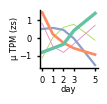

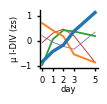

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(0.75,0.75))  
sns.lineplot(data = meldted_tpm, x = 'd', y = 'tpm_mean', hue='k',palette=colorpalette_tpm, hue_order = list(meldted_tpm.sort_values('ngenes')['k'].unique()), size='ngenes', ax = ax, legend=False)
ax.set_xticks(sorted(meldted_tpm['d'].unique()))
ax.set_xticklabels(sorted(meldted_tpm['d'].unique()))

style_axis(ax)
ax.set(xlabel='day', ylabel='TPM mean (zs)')
sns.despine()
fig.savefig('figs_Ulicevic/' + 'tpm' + '.clsuters.lineplot.png', format = 'png', dpi=300, bbox_inches = 'tight')


fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(0.75,0.75))
sns.lineplot(data = meldted_div, x = 'd', y = 'div_mean', hue='k', palette=colorpalette_div, hue_order = list(meldted_div.sort_values('ngenes')['k'].unique()),size='ngenes', ax = ax, legend=False)
style_axis(ax)
ax.set(xlabel='day', ylabel='I-DIV mean (zs)')
ax.set_xticks(sorted(meldted_div['d'].unique()))
ax.set_xticklabels(sorted(meldted_div['d'].unique()))
sns.despine()
fig.savefig('figs_Ulicevic/' + 'div' + '.clsuters.lineplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

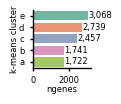

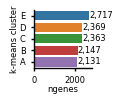

In [ ]:
fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.barplot(data = meldted_tpm.drop_duplicates('k')[['k', 'ngenes']], y = 'k', x='ngenes', hue='k', order = meldted_tpm.sort_values('ngenes', ascending=False).drop_duplicates('ngenes').k.to_list(),
            palette=colorpalette_tpm, orient='h',
            dodge=False, ax=ax)
ax.set_yticklabels([tpm_switchclusternames[y.get_text()] for y in ax.get_yticklabels()])
ax.set_ylabel('k-means cluster')
style_axis(ax)
sns.despine()


for i,v in meldted_tpm.drop_duplicates('k')[['k', 'ngenes']].set_index('k')['ngenes'].to_dict().items():
    plt.text(y=i, x = v, s=f'{v:,}', va='center', fontsize=6)

fig.savefig('figs_Ulicevic/' + 'tpm' + '.clsuters.barplot.png', format = 'png', dpi=300, bbox_inches = 'tight')
fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.barplot(data = meldted_div.drop_duplicates('k')[['k', 'ngenes']], y = 'k', x='ngenes', hue='k', order = meldted_div.sort_values('ngenes', ascending=False).drop_duplicates('ngenes').k.to_list(),
            palette=colorpalette_div, orient='h',
            dodge=False, ax=ax)
ax.set_yticklabels([div_switchclusternames[y.get_text()] for y in ax.get_yticklabels()])
ax.set_ylabel('k-means cluster')
style_axis(ax)
sns.despine()

for i,v in meldted_div.drop_duplicates('k')[['k', 'ngenes']].set_index('k')['ngenes'].to_dict().items():
    plt.text(y=i, x = v, s=f'{v:,}', va='center', fontsize=6)

fig.savefig('figs_Ulicevic/' + 'div' + '.clsuters.barplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

In [ ]:
enrichr_tpm = pd.concat([do_enrichr(glist=gene_info.loc[cls_df_mean_tpm[cls_df_mean_tpm.km_tpm == k].index, 'gene_name'].to_list(), background_genelist = gene_info.loc[cls_df_mean_tpm.index, 'gene_name'].to_list(), gr=k) for k in cls_df_mean_tpm.km_tpm.unique() ]).assign(metric='TPM')
enrichr_div = pd.concat([do_enrichr(glist=gene_info.loc[cls_df_mean_div[cls_df_mean_div.km_div == k].index, 'gene_name'].to_list(), background_genelist = gene_info.loc[cls_df_mean_div.index, 'gene_name'].to_list(), gr=k) for k in cls_df_mean_div.km_div.unique() ]).assign(metric='I-DIV')

# enrichr_tpm.to_csv('tables_Ulicevic/enrichr_tpm.csv.gz', index=False)
# enrichr_div.to_csv('tables_Ulicevic/enrichr_div.csv.gz', index=False)
enrichr_tpm.to_csv(source_data_path + 'S6ghij.csv.gz', index=False)
enrichr_div.to_csv(source_data_path + '5f.csv.gz', index=False)
enrichr_tpm.to_csv(tables_main_path + 'enrichr_tpm.csv.gz', index=False)
enrichr_div.to_csv(tables_main_path + 'enrichr_div.csv.gz', index=False)

In [ ]:
# meldted_tpm = pd.read_csv('tables_Ulicevic/cls_df_mean_tpm.melted.csv.gz')
# meldted_div = pd.read_csv('tables_Ulicevic/cls_df_mean_div.melted.csv.gz')

enrichr_tpm = pd.read_csv('tables_Ulicevic/enrichr_tpm.csv.gz')
enrichr_div = pd.read_csv('tables_Ulicevic/enrichr_div.csv.gz')
enrichr_tpm.kmcluster = enrichr_tpm.kmcluster.map(tpm_switchclusternames)
enrichr_div.kmcluster = enrichr_div.kmcluster.map(div_switchclusternames)
# colorpalette_tpm= {g: sns.color_palette('Set2')[i] for i,g in enumerate(sorted(enrichr_tpm.kmcluster.unique())) }
# colorpalette_div= {g: sns.color_palette('tab10')[i] for i,g in enumerate(sorted(enrichr_div.kmcluster.unique()))  }

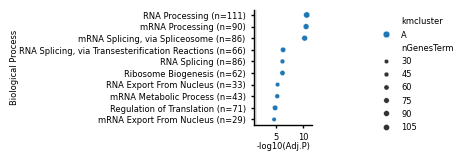

In [ ]:
gset= 'GO_Biological_Process_2025'

# label_abbrev = {
#     "RNA Processing (n=111)": "RNA Processing (n=111)",
#     "mRNA Processing (n=90)": "mRNA Processing (n=90)",
#     "mRNA Splicing, via Spliceosome (n=85)": "mRNA Splicing, via Spliceosome (n=85)",
#     "Ribosome Biogenesis (n=62)": "Ribosome Biogenesis (n=62)",
#     "RNA Splicing (n=85)": "RNA Splicing (n=85)",
#     # "RNA Splicing, via Transesterification Reactions With Bulged Adenosine as Nucleophile (n=65)": "RNA Splicing, via Transesterif. Rxns w/ Bulged Adenosine as Nucleoph. (n=65)",
#     "RNA Splicing, via Transesterification Reactions With Bulged Adenosine as Nucleophile (n=65)": "RNA Splicing, via Transesterification Reactions (n=65)",
#     "RNA Export From Nucleus (n=33)": "RNA Export From Nucleus (n=33)",
#     "mRNA Metabolic Process (n=43)": "mRNA Metab. Process (n=43)",
#     "Regulation of Translation (n=71)": "Reg. of Transl. (n=71)",
#     "mRNA Export From Nucleus (n=29)": "mRNA Export From Nucleus (n=29)",
# }

plot_df = enrichr_div[(enrichr_div.Gene_set == gset) & (enrichr_div['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
fig, ax = plt.subplots(figsize=(0.75,len(plot_df)/6.7))
sns.scatterplot(data = plot_df, x = '-log10(Adjusted P-value)', y ='Term', hue='kmcluster', ax=ax, 
                palette=colorpalette_div, size='nGenesTerm',zorder = 3, sizes = (10,20))
ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
ax.set(ylabel = 'Biological Process', xlabel = '-log10(Adj.P)')
ax.set_xlim(ax.get_xlim()[0] * 1.05, ax.get_xlim()[1] * 1.05)


labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]

labels = [label + f' (n={list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)

label_abbrev = {y.get_text(): y.get_text() for y in ax.get_yticklabels()}
label_abbrev = {y: y.replace('RNA Splicing, via Transesterification Reactions With Bulged Adenosine as Nucleophile', 'RNA Splicing, via Transesterification Reactions') for y in label_abbrev.keys()}

# ax.set_yticklabels([y.get_text().replace('Macromolecule', 'Macromol.').replace('Biosynthetic', 'Biosynth.').replace('Translation', 'Transl.').replace('Metabolic', 'Metab.').replace('Transesterification','Transesterif.').replace('With', 'w/').replace('Reactions','Rxns').replace('Nucleophile', 'Nucleoph.') for y in ax.get_yticklabels()])
ax.set_yticklabels([label_abbrev[y.get_text()] for y in ax.get_yticklabels()])

style_axis(ax)
ax.legend(bbox_to_anchor=(2,1), frameon=False)
sns.despine()
fig.savefig('figs_Ulicevic/' + 'div' + '.clsuters.enrichr.png', format = 'png', dpi=300, bbox_inches = 'tight')

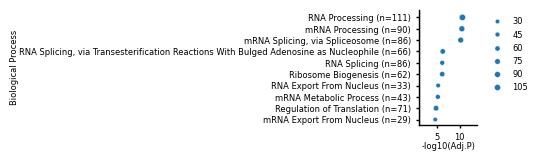

In [ ]:
gset= 'GO_Biological_Process_2025'
for k in enrichr_div.kmcluster.unique():
    plot_df = enrichr_div[(enrichr_div.Gene_set == gset) & (enrichr_div.kmcluster == k) & (enrichr_div['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
    if len(plot_df) > 0:
        fig, ax = plt.subplots(figsize=(0.75,len(plot_df)/6.7))
        sns.scatterplot(data = plot_df, x = '-log10(Adjusted P-value)', y ='Term', ax=ax, 
                        color=colorpalette_div[k], size='nGenesTerm',zorder = 3, sizes = (10,20))
        ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
        ax.set(ylabel = 'Biological Process', xlabel = '-log10(Adj.P)')
        ax.set_xlim(ax.get_xlim()[0] * 1.05, ax.get_xlim()[1] * 1.05)


        labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
        labels = [label + f' (n={list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
        ax.set_yticklabels(labels)
        
        
        label_abbrev = {y.get_text(): y.get_text() for y in ax.get_yticklabels()}
        label_abbrev = {y: y.replace('RNA Splicing, via Transesterification Reactions With Bulged Adenosine as Nucleophile', 'RNA Splicing, via Transesterification Reactions') for y in label_abbrev.keys()}

        
        ax.set_xlim(ax.set_xlim()[0] * 1.2,ax.set_xlim()[1] * 1.2  )
        ax.set_ylim(ax.set_ylim()[0],ax.set_ylim()[1] * 1.5  )
        style_axis(ax)
        ax.legend(bbox_to_anchor=(2,1), frameon=False)
        sns.despine()
        fig.savefig('figs_Ulicevic/' + 'div' + f'.clsuter_{k}.enrichr.png', format = 'png', dpi=300, bbox_inches = 'tight')

In [ ]:
enrichr_div.loc[enrichr_div['Adjusted P-value'] < 0.05].kmcluster.value_counts().to_csv('tables_Ulicevic/n_enriched_terms_per_cluster.div.csv.gz', index=True)
enrichr_tpm.loc[enrichr_tpm['Adjusted P-value'] < 0.05].kmcluster.value_counts().to_csv('tables_Ulicevic/n_enriched_terms_per_cluster.tpm.csv.gz', index=True)

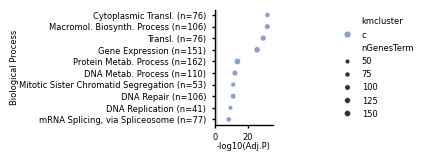

In [ ]:

# label_abbrev = {
#     "Cytoplasmic Translation (n=75)": "Cytoplasmic Transl. (n=75)",
#     "Macromolecule Biosynthetic Process (n=103)": "Macromol. Biosynth. Process (n=103)",
#     "Translation (n=75)": "Transl. (n=75)",
#     "Gene Expression (n=149)": "Gene Expression (n=149)",
#     "Protein Metabolic Process (n=158)": "Protein Metab. Process (n=158)",
#     "DNA Metabolic Process (n=110)": "DNA Metab. Process (n=110)",
#     "Mitotic Sister Chromatid Segregation (n=53)": "Mitotic Sister Chromatid Segregation (n=53)",
#     "DNA Repair (n=105)": "DNA Repair (n=105)",
#     "DNA Replication (n=41)": "DNA Replication (n=41)",
#     "RNA Splicing, via Transesterification Reactions With Bulged Adenosine as Nucleophile (n=67)": "RNA Splicing, via Transesterif. Rxns w/ Bulged Adenosine as Nucleoph. (n=67)",
# }

gset= 'GO_Biological_Process_2025'
plot_df = enrichr_tpm[(enrichr_tpm.Gene_set == gset) & (enrichr_tpm['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
fig, ax = plt.subplots(figsize=(0.75,len(plot_df)/6.7))
sns.scatterplot(data = plot_df, x = '-log10(Adjusted P-value)', y ='Term', hue='kmcluster', ax=ax, 
                palette=colorpalette_tpm, size='nGenesTerm',zorder = 3, sizes = (10,20))
ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
ax.set(ylabel = 'Biological Process', xlabel = '-log10(Adj.P)')
ax.set_xlim(ax.get_xlim()[0] * 1.05, ax.get_xlim()[1] * 1.05)


labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
labels = [label + f' (n={list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
ax.set_yticklabels(labels)
ax.set_yticklabels([y.get_text().replace('Macromolecule', 'Macromol.').replace('Biosynthetic', 'Biosynth.').replace('Translation', 'Transl.').replace('Metabolic', 'Metab.').replace('Transesterification','Transesterif.').replace('With', 'w/').replace('Reactions','Rxns').replace('Nucleophile', 'Nucleoph.') for y in ax.get_yticklabels()])

style_axis(ax)
ax.legend(bbox_to_anchor=(2,1), frameon=False)
sns.despine()

fig.savefig('figs_Ulicevic/' + 'tpm' + '.clsuters.enrichr.png', format = 'png', dpi=300, bbox_inches = 'tight')

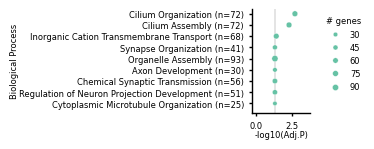

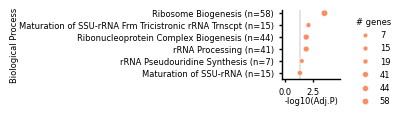

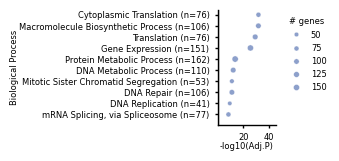

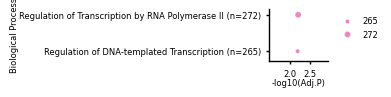

In [ ]:
gset= 'GO_Biological_Process_2025'
for k in enrichr_tpm.kmcluster.unique():
    plot_df = enrichr_tpm[(enrichr_tpm.Gene_set == gset) & (enrichr_tpm.kmcluster == k) & (enrichr_tpm['Adjusted P-value'] < 0.05)].sort_values('Adjusted P-value').head(10)
    if len(plot_df) > 2:
        fig, ax = plt.subplots(figsize=(0.75,len(plot_df)/6.7))
        sns.scatterplot(data = plot_df, x = '-log10(Adjusted P-value)', y ='Term', ax=ax, color=colorpalette_tpm[k], size='nGenesTerm',zorder = 3, sizes = (10,20))
        ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
        ax.set(ylabel = 'Biological Process', xlabel = '-log10(Adj.P)')
        ax.set_xlim(ax.get_xlim()[0] * 1.05, ax.get_xlim()[1] * 1.05)


        labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
        labels = [label + f' (n={list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
        ax.set_yticklabels(labels)
        # ax.set_yticklabels([label_abbrev[y] for y in ax.get_yticklabels()])
        ax.set_xlim(ax.set_xlim()[0] * -0.2,ax.set_xlim()[1] * 1.3  )
        ax.set_ylim(ax.set_ylim()[0] * 1.05,ax.set_ylim()[1] )
        style_axis(ax)
        ax.legend(bbox_to_anchor=(2,1), frameon=False, title='# genes')
        sns.despine()
        fig.savefig('figs_Ulicevic/' + 'tpm' + f'.clsuter_{k}.enrichr.png', format = 'png', dpi=300, bbox_inches = 'tight')
    elif len(plot_df) == 2:
        fig, ax = plt.subplots(figsize=(0.75,len(plot_df)/3))
        sns.scatterplot(data = plot_df, x = '-log10(Adjusted P-value)', y ='Term', ax=ax, color=colorpalette_tpm[k], size='nGenesTerm',zorder = 3, sizes = (10,20))
        ax.axvline(-np.log10(0.05), color='silver', alpha = 0.5)
        ax.set(ylabel = 'Biological Process', xlabel = '-log10(Adj.P)')
        # ax.set_xlim(ax.get_xlim()[0] * -1.05, ax.get_xlim()[1] * 1.05)


        labels_raw = [y.get_text()[:y.get_text().find(' (GO:')] for y in ax.get_yticklabels()]
        labels = [label + f' (n={list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])[0]})' if len(list(plot_df.loc[plot_df.Term.str.contains(label, na=False), "nGenesTerm"])) > 0 else label for label in labels_raw]
        ax.set_yticklabels(labels)
        # ax.set_yticklabels([label_abbrev[y] for y in ax.get_yticklabels()])
        ax.set_xlim(ax.set_xlim()[0] * 1.2,ax.set_xlim()[1] * 1.3  )
        ax.set_ylim(ax.set_ylim()[0] * 1.2,ax.set_ylim()[1] * 3 )
        style_axis(ax)
        ax.legend(bbox_to_anchor=(2,1), frameon=False)
        sns.despine()
        fig.savefig('figs_Ulicevic/' + 'tpm' + f'.clsuter_{k}.enrichr.png', format = 'png', dpi=300, bbox_inches = 'tight')

In [ ]:
def pval_to_asterisks(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.01:
        return '**'
    elif p <= 0.05:
        return '*'
    else:
        return ''

def get_isoforms_limma(gene):
    if gene[:4] != 'ENSG':
        gid = gene_info.loc[gene_info['gene_name'] == gene].index[0]
    else:
        gid = gene
    
    isoforms_limma = pd.read_csv(input_data_path + f'isoform_day0_day5_de/{gid}/{gid}.day0.day5.isoform.limma.csv.gz').merge(gene_info.gene_name, left_on='gene_id', right_index=True)
    gene_pvals = isoforms_limma[['transcript_id', 'P.Value']].set_index('transcript_id')
    gene_astrc = gene_pvals.applymap(pval_to_asterisks)
    return gene_astrc


def get_isoforms_from_gene(gene):
    ''' This function gets a gene name or gene id and returns the isoforms of this gene with their expression values in the transcript_tpm.csv.gz file.
    Args:
        gene: A string which is either a gene name or a gene id.
    Returns:
        A dataframe which contains the isoforms of the gene with their expression values in the transcript_tpm.csv.gz file.
    '''
    if gene[:4] != 'ENSG':
        gid = gene_info.loc[gene_info['gene_name'] == gene].index[0]
    else:
        gid = gene
    rows = pd.read_csv(input_data_path + 'transcript_tpm.csv.gz', usecols=['accession_number'])
    rows_to_skip = rows[~rows['accession_number'].str.contains(gid)].index + 1
    isof_df = pd.read_csv(input_data_path + 'transcript_tpm.csv.gz', skiprows=rows_to_skip, index_col='transcript_id').drop(columns='Unnamed: 0')
    return isof_df
def isoform_expression_barplots(gene,isoforms_df, savefig=False):
    melted_df = isoforms_df.reset_index()[['transcript_id'] + tinfo.index.to_list()].melt(id_vars=['transcript_id'])
    melted_df['tpm_log2'] = melted_df['value'].apply(lambda x: math.log2(x+1))
    melted_df = melted_df.merge(tinfo.day, left_on='variable', right_index=True)
    oorder = melted_df.groupby('transcript_id')['value'].mean().sort_values(ascending=False).index

    fig, ax = plt.subplots(figsize=(len(isoforms_df)/4,0.75))
    sns.barplot(data = melted_df,  x = 'transcript_id', y ='tpm_log2', errorbar='se', 
                hue='day', hue_order = sorted(melted_df.day.unique()), palette=differential_color_palette, # flare
                order = oorder,
                err_kws={"color": "dimgrey", "linewidth": 0.75}) # errorbars of standard deviation
    ax.legend(bbox_to_anchor=(1.1,1), frameon=False)
    # xticks = [x.get_text()[len('ENST0000'):] for x in ax.get_xticklabels()]
    xticks = [x.get_text().split('.')[0] for x in ax.get_xticklabels()]
    ax.set_xticklabels(xticks, rotation=35, ha='right', y = 0.1)
    # ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')


    ax.tick_params(length=2.5, bottom=False)
    ax.set_yticklabels(ax.get_yticklabels(), x=0)
    ax.set_xlabel(ax.get_xlabel(), labelpad=0)
    ax.set_ylabel(ax.get_ylabel(), labelpad=0)

    ax.set(ylabel='Isoform level\nTPM [log2]', xlabel='isoforms')
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)     
    ax.patch.set_facecolor('None')
    
    # add asteriks 
    gene_astrc = get_isoforms_limma(gene=gene)
    line_y = ax.get_ylim()[1] +0.5
    asterisk_y = line_y +0.05
    for idx, transcript in enumerate(oorder):
        significance = gene_astrc.loc[transcript,'P.Value']
        if significance:
            ax.text(x=idx+0.1,y=asterisk_y,s=significance,ha='center',va='bottom')
            ax.hlines(y=line_y,xmin=idx - 0.3,xmax=idx + 0.3,color='black',linewidth=0.7)
        else:
            ax.text(x=idx+0.1,y=asterisk_y + 0.12,s='ns',ha='center',va='bottom')
            ax.hlines(y=line_y ,xmin=idx - 0.3,xmax=idx + 0.3,color='black',linewidth=0.7)  

    if savefig:
        fig.savefig('figs_Ulicevic/' + gene + '.barplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

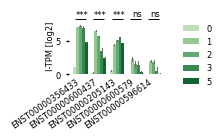

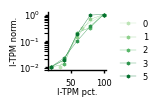

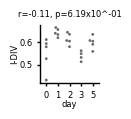

In [ ]:
DLL3_isoforms = get_isoforms_from_gene(gene='DLL3')
isoform_expression_barplots(gene='DLL3',isoforms_df=DLL3_isoforms, savefig=True)
isoform_meanexpression_lineplot(isoforms_df=DLL3_isoforms, gn='DLL3', savefig=True)
swamplot_df = tinfo.assign(DLL3 = div.loc[gene_info.loc[gene_info.gene_name=='DLL3'].index[0]]) 

fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.swarmplot(data=tinfo.assign(DLL3 = div.loc[gene_info.loc[gene_info.gene_name=='DLL3'].index[0]]), 
              x='day', y='DLL3', order=sorted(tinfo.day.unique()), c = 'dimgrey', s=2, edgecolor='None')
style_axis(ax)
sns.despine()
ax.set_ylabel('I-DIV')
r, p = st.spearmanr(swamplot_df['day'], swamplot_df['DLL3'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'DLL3' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

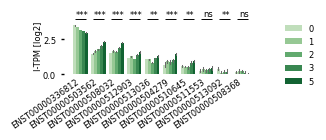

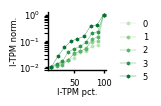

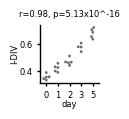

In [ ]:
DHX15_isoforms = get_isoforms_from_gene(gene='DHX15')
isoform_expression_barplots(gene='DHX15',isoforms_df=DHX15_isoforms, savefig=True)
isoform_meanexpression_lineplot(isoforms_df=DHX15_isoforms, gn='DHX15', savefig=True)
fig, ax = plt.subplots(figsize=(0.75, 0.75))
swamplot_df = tinfo.assign(DHX15 = div.loc[gene_info.loc[gene_info.gene_name=='DHX15'].index[0]]) 
sns.swarmplot(data=swamplot_df, 
              x='day', y='DHX15', order=sorted(tinfo.day.unique()), c = 'dimgrey', s=2, edgecolor='None')
style_axis(ax)
sns.despine()
ax.set_ylabel('I-DIV')
r, p = st.spearmanr(swamplot_df['day'], swamplot_df['DHX15'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'DHX15' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

DHX15_isoforms.to_csv(source_data_path + '5hi.csv.gz')
swamplot_df.to_csv(source_data_path + '5g.csv.gz')

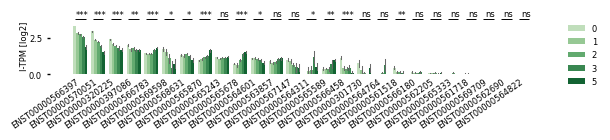

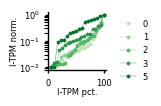

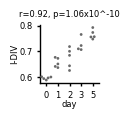

In [ ]:
RNPS1_isoforms = get_isoforms_from_gene(gene='RNPS1')
isoform_expression_barplots(gene='RNPS1',isoforms_df=RNPS1_isoforms, savefig=True)
isoform_meanexpression_lineplot(isoforms_df=RNPS1_isoforms, gn='RNPS1', savefig=True)

swamplot_df = tinfo.assign(RNPS1 = div.loc[gene_info.loc[gene_info.gene_name=='RNPS1'].index[0]]) 

fig, ax = plt.subplots(figsize=(0.75, 0.75))
sns.swarmplot(data=swamplot_df, 
              x='day', y='RNPS1', order=sorted(tinfo.day.unique()), c = 'dimgrey', s=2, edgecolor='None')
style_axis(ax)
sns.despine()
ax.set_ylabel('I-DIV')
r, p = st.spearmanr(swamplot_df['day'], swamplot_df['RNPS1'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'RNPS1' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

DHX15_isoforms.to_csv(source_data_path + 'S6ef.csv.gz')
swamplot_df.to_csv(source_data_path + 'S6d.csv.gz')

# T-DIV

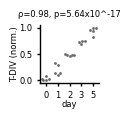

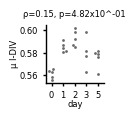

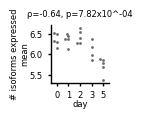

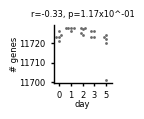

In [ ]:
fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.swarmplot(data = tinfo, x = 'day', y = 'T-DIV norm', order = sorted(tinfo.day.unique()), c='dimgrey', s=2)
ax.set_ylabel('T-DIV (norm)')
style_axis(ax) ; sns.despine()
ax.set_ylabel('T-DIV (norm.)')
r, p = st.spearmanr(tinfo['day'], tinfo['T-DIV norm'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'tdiv' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.swarmplot(data = tinfo, x = 'day', y = 'meanisofdiv', order = sorted(tinfo.day.unique()), c='dimgrey', s=2)
ax.set(ylabel = 'µ I-DIV')
style_axis(ax) ; sns.despine()
r, p = st.spearmanr(tinfo['day'], tinfo['meanisofdiv'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'midiv' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight')

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.swarmplot(data = tinfo, x = 'day', y = 'meanNIS', order = sorted(tinfo.day.unique()), c='dimgrey', s=2)
# ax.set(ylabel = 'µ NIS')
ax.set(ylabel = '# isoforms expressed\nmean')
style_axis(ax) ; sns.despine()
r, p = st.spearmanr(tinfo['day'], tinfo['meanNIS'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'mnis' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight', pad_inches=0.5)

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.swarmplot(data = tinfo, x = 'day', y = 'nGenes_expressed', order = sorted(tinfo.day.unique()), c='dimgrey', s=2)
ax.set(ylabel = '# genes')
style_axis(ax) ; sns.despine()
r, p = st.spearmanr(tinfo['day'], tinfo['nGenes_expressed'])
ax.set_title(f'ρ={r:.2f}, {c(p).replace("e", "x10^")}')
fig.savefig('figs_Ulicevic/' + 'ngenes' + '.swarmplot.png', format = 'png', dpi=300, bbox_inches = 'tight')
tinfo.to_csv(source_data_path + '5bc_S6a.csv.gz')

# proteomics

[link](https://doi.org/10.6019/PXD046084)

files found at: 
[link](https://www.ebi.ac.uk/pride/archive/projects/PXD046084)  
[link](https://ftp.pride.ebi.ac.uk/pride/data/archive/2024/04/PXD046084/)

`wget -r --no-parent ftp://ftp.pride.ebi.ac.uk/pride/data/archive/2024/04/PXD046084/`

In [24]:
import sys
sys.path.append('..')  # div.py lives in the repository root
from div import *
import zipfile
import pandas as pd

with zipfile.ZipFile(zip_path) as z:
    with z.open("txt/proteinGroups.txt") as f:
        df = pd.read_csv(f, sep="\t")

# df = df[~df['Gene names'].str.upper().str.contains('|'.join(list(gene_info.loc[gene_info.RP_only == True,'gene_name'])), na=False)]
df = df[df['Gene names'].str.upper().str.contains('|'.join(list(gene_info.loc[genes_for_tdiv,'gene_name'])), na=False)]
df = df.select_dtypes(include = 'number').drop(columns = 'id').fillna(0)
df = df[df >=0].dropna(axis='columns')
pdiv = df.apply(lambda x: DIV(arr=x, spreading_percentage=1, tpm_or_count='tpm', ceil=False, min_eve=0), axis = 'rows')
del df
pdiv.name= 'P-DIV'
pdiv_df = pdiv.filter(like='Unique peptides Day').to_frame()

div_min, div_max = min(pdiv_df['P-DIV']), max(pdiv_df['P-DIV'])
div_range = div_max - div_min
pdiv_df['P-DIV norm'] = pdiv_df['P-DIV'].apply(lambda x: (x - div_min) / div_range)

pdiv_df.reset_index(inplace=True)
pdiv_df = pdiv_df.rename(columns = {'index': 'smpl'})
pdiv_df.smpl=pdiv_df.smpl.str.replace('Unique peptides Day', '')
pdiv_df['day']=pdiv_df.smpl.str.split('-', expand=True)[0].astype(int)



# pdiv_df.to_csv('tables_Ulicevic/P-DIV.csv.gz', compression='gzip')
# pdiv_df.to_csv(tables_main_path + 'P-DIV.csv.gz', compression='gzip')


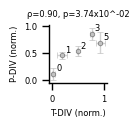

In [25]:

pdiv_tdiv_df = tinfo.groupby('day')['T-DIV' + ' norm'].mean().to_frame().join(pdiv_df.groupby('day')['P-DIV' + ' norm'].mean()).add_suffix('_mean')
pdiv_tdiv_df = pdiv_tdiv_df.join( tinfo.groupby('day')['T-DIV' + ' norm'].std().to_frame().join(pdiv_df.groupby('day')['P-DIV' + ' norm'].std()).add_suffix('_std')  )
# pdiv_tdiv_df = pdiv_tdiv_df.sort_index()
fig, ax = plt.subplots(figsize=(0.75,0.75))
ax.errorbar(x = pdiv_tdiv_df['T-DIV norm_mean'], y = pdiv_tdiv_df['P-DIV norm_mean'], 
                        xerr=pdiv_tdiv_df['T-DIV norm_std'], yerr=pdiv_tdiv_df['P-DIV norm_std'],
                        ecolor='silver', elinewidth=1, alpha=0.7, ms=3.5,capsize=2,mec='dimgrey',mew=0.7,
                        markerfacecolor='silver', fmt='h')

ax.set(xlabel = 'T-DIV (norm.)', ylabel = 'P-DIV (norm.)') 

for day, row in pdiv_tdiv_df.iterrows():
    ax.annotate(
        str(day),
        xy=(row['T-DIV norm_mean'], row['P-DIV norm_mean']),
        xytext=(2, 2),
        textcoords='offset points',
        fontsize=6
    )
r, p = st.spearmanr(pdiv_tdiv_df['T-DIV norm_mean'], pdiv_tdiv_df['P-DIV norm_mean'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
sns.despine()
# fig.savefig('figs_Ulicevic/Pdiv_Tdiv.png', format='png', dpi=300, bbox_inches = 'tight')
# pdiv_tdiv_df.to_csv(source_data_path + 'Sb.csv.gz')

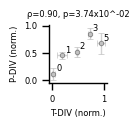

In [ ]:

pdiv_tdiv_df = tinfo.groupby('day')['T-DIV' + ' norm'].mean().to_frame().join(pdiv_df.groupby('day')['P-DIV' + ' norm'].mean()).add_suffix('_mean')
pdiv_tdiv_df = pdiv_tdiv_df.join( tinfo.groupby('day')['T-DIV' + ' norm'].std().to_frame().join(pdiv_df.groupby('day')['P-DIV' + ' norm'].std()).add_suffix('_std')  )
# pdiv_tdiv_df = pdiv_tdiv_df.sort_index()
fig, ax = plt.subplots(figsize=(0.75,0.75))
ax.errorbar(x = pdiv_tdiv_df['T-DIV norm_mean'], y = pdiv_tdiv_df['P-DIV norm_mean'], 
                        xerr=pdiv_tdiv_df['T-DIV norm_std'], yerr=pdiv_tdiv_df['P-DIV norm_std'],
                        ecolor='silver', elinewidth=1, alpha=0.7, ms=3.5,capsize=2,mec='dimgrey',mew=0.7,
                        markerfacecolor='silver', fmt='h')

ax.set(xlabel = 'T-DIV (norm.)', ylabel = 'P-DIV (norm.)') 

for day, row in pdiv_tdiv_df.iterrows():
    ax.annotate(
        str(day),
        xy=(row['T-DIV norm_mean'], row['P-DIV norm_mean']),
        xytext=(2, 2),
        textcoords='offset points',
        fontsize=6
    )
r, p = st.spearmanr(pdiv_tdiv_df['T-DIV norm_mean'], pdiv_tdiv_df['P-DIV norm_mean'])
ax.set_title(f'ρ={r:.2f}, {annotpval(p).replace("e", "x10^")}')
sns.despine()
fig.savefig('figs_Ulicevic/Pdiv_Tdiv.png', format='png', dpi=300, bbox_inches = 'tight')
pdiv_tdiv_df.to_csv(source_data_path + 'Sb.csv.gz')

# gene groups

In [34]:
tdiv_genegroups

,day,11728_DIV,RP_DIV,RP_excluded_DIV
day0_1,0,0.861924,0.884795,0.891234
day0_2,0,0.859576,0.884187,0.889952
day0_3,0,0.859042,0.883782,0.889310
day0_4,0,0.859363,0.884187,0.889631
day0_5,0,0.860003,0.884187,0.890272
day1_1,1,0.862138,0.881148,0.893158
day1_2,1,0.861390,0.880742,0.892516
day1_3,1,0.862244,0.881148,0.892944
day1_4,1,0.869608,0.884593,0.896898
day1_5,1,0.870035,0.884187,0.898073


In [27]:
columns_to_comapre = [f'{len(gene_info)}_DIV', 'RP_DIV', 'RP_excluded_DIV']
global_min = tdiv_genegroups[columns_to_comapre][tdiv_genegroups[columns_to_comapre] > 0].min().min()
global_max = tdiv_genegroups[columns_to_comapre][tdiv_genegroups[columns_to_comapre] > 0].max().max()

normzlied_tdivs = tdiv_genegroups[[]]
for c in columns_to_comapre:
    normzlied_tdivs[c] = tdiv_genegroups[c].apply(lambda x: (x - global_min)/(global_max-global_min)     )
normzlied_tdivs = normzlied_tdivs.join(tdiv_genegroups.day)
del tdiv_genegroups

Text(0, 0.5, 'T-DIV (norm.)')

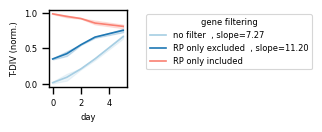

In [ ]:
gene_group_colors = dict(zip([f'{len(gene_info)}_DIV','RP_excluded_DIV'],sns.color_palette('Paired', n_colors=2)))
fig, ax = plt.subplots(figsize=(1,1))
for c in [f'{len(gene_info)}_DIV','RP_excluded_DIV']:
    sns.lineplot(data = normzlied_tdivs, y = c, x = 'day', label= c.replace('_', ' ') + f', slope={np.polyfit(normzlied_tdivs[c], normzlied_tdivs['day'], 1)[0]:.2f}', c=gene_group_colors[c], alpha = 1, zorder = 1)
sns.lineplot(data = normzlied_tdivs, y = 'RP_only_included', x = 'day', label= 'RP only included'+ f', slope={np.polyfit(normzlied_tdivs['RP_only_included'], normzlied_tdivs['day'], 1)[0]:.2f}', c='salmon', zorder = 2)
ax.legend(bbox_to_anchor=(1.2,1), title='gene filtering', frameon=False)
ax.set_ylabel('T-DIV (norm.)')
ax.set_xticks(sorted(normzlied_tdivs['day'].unique()))
ax.set_xticklabels(sorted(normzlied_tdivs['day'].unique()))

fig.savefig('figs_Ulicevic/gene_groups.lineplot.png',format='png', dpi=300, bbox_inches = 'tight')
